In [10]:
import sys
sys.path.append("../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA 
from data import (DATASET_NAMES,LABEL_FRACTIONS,hide_labels,load_dataset,scale_features,split_data)

In [11]:
SEED=1
NORMAL_COLOR="tab:blue"
ANOMALY_COLOR="tab:red"
LINE_COLORS=["tab:blue","tab:red","tab:green","tab:orange","tab:brown","tab:purple",
             "tab:pink","tab:gray","tab:olive"]
LARGER_NAMES=["satellite","landsat","magic_gamma"]   # the 3 larger ADBench datasets
ALL_NAMES=DATASET_NAMES+LARGER_NAMES
data = {name:load_dataset(name) for name in ALL_NAMES}

**Dataset Summary Table**

In [12]:
summary = pd.DataFrame([
    {"dataset":name,"samples":len(y),"features":X.shape[1],
     "anomalies":int(y.sum()),"anomaly %":round(100*y.mean(),1),
     "missing_values":int(np.isnan(X).sum())}
    for name , (X,y) in data.items()  
]).set_index("dataset")
summary

,samples,features,anomalies,anomaly %,missing_values
dataset,,,,,
annthyroid,7200,6,534,7.4,0
cardiotocography,2114,21,466,22.0,0
breastw,683,9,239,35.0,0
lymphography,148,18,6,4.1,0
vertebral,240,6,30,12.5,0
hepatitis,80,19,13,16.2,0
satellite,6435,36,2036,31.6,0
landsat,6435,36,1333,20.7,0
magic_gamma,19020,10,6688,35.2,0


**Anomaly Rate per dataset**

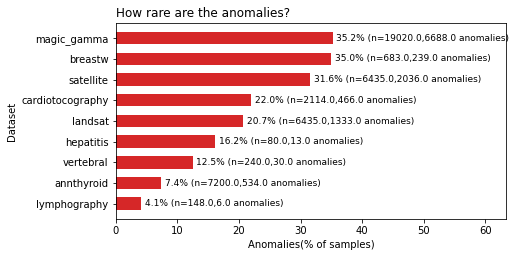

In [13]:
names=summary.sort_values("anomaly %").index
fig, ax = plt.subplots(figsize=(7,3.6))
bars=ax.barh(names,summary.loc[names,"anomaly %"],color=ANOMALY_COLOR,height=0.6)
for bar,name in zip(bars,names):
    r=summary.loc[name]
    ax.text(bar.get_width()+0.6,bar.get_y()+bar.get_height()/2,f"{r['anomaly %']}% (n={r['samples']},{r['anomalies']} anomalies)",va="center",fontsize=9)
ax.set_xlim(0,summary["anomaly %"].max()*1.8)
ax.set_xlabel("Anomalies(% of samples)")
ax.set_ylabel("Dataset")
ax.set_title("How rare are the anomalies?",loc="left")
plt.show() 

**PCA Scatter: Separability of Anomalies**

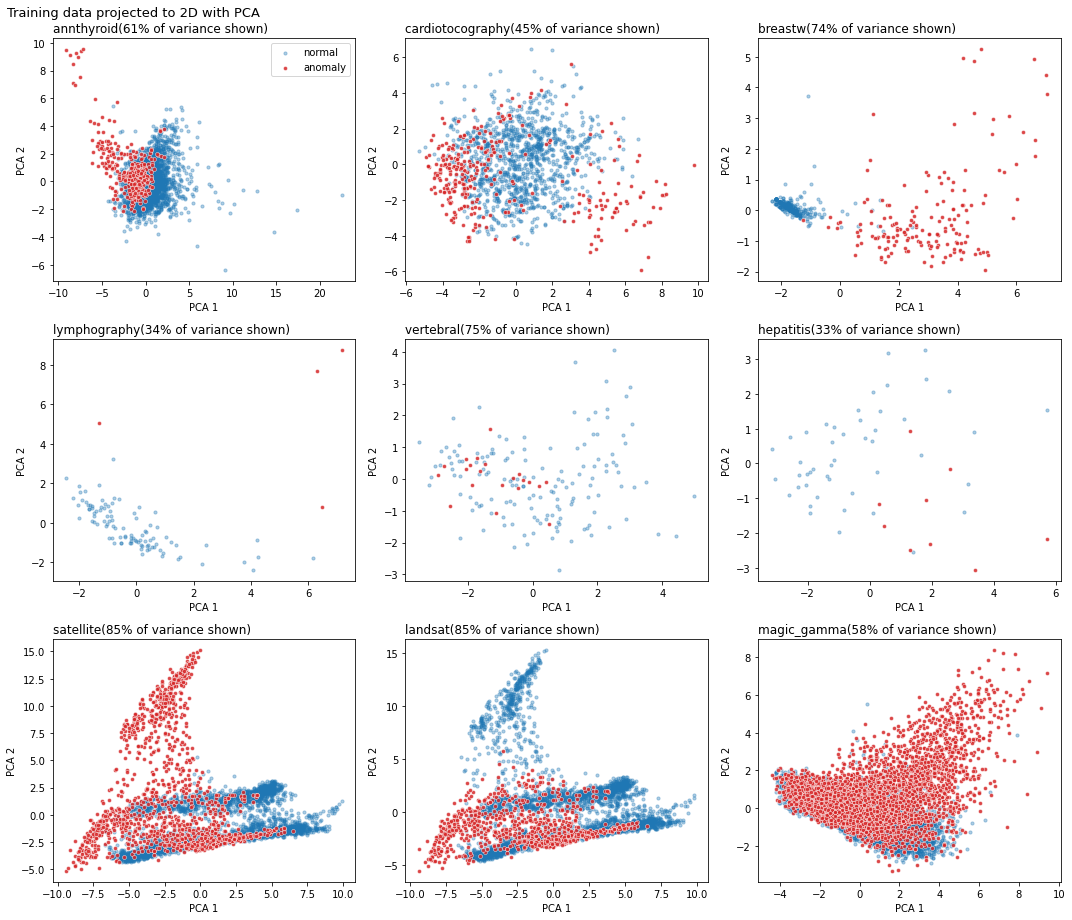

In [14]:
fig,axes=plt.subplots(3,3,figsize=(15,13))
for ax,(name , (X,y)) in zip(axes.flat,data.items()):
    X_train,X_test,y_train,y_test=split_data(X,y,seed=SEED)
    X_train,X_test=scale_features(X_train,X_test) #same scaling as training
    pca=PCA(n_components=2,random_state=SEED).fit(X_train) #find best 2 directions
    Z=pca.transform(X_train)
    ax.scatter(Z[y_train==0,0],Z[y_train==0,1],s=10,alpha=0.35,color=NORMAL_COLOR,label="normal")
    ax.scatter(Z[y_train==1,0],Z[y_train==1,1],s=16,alpha=0.85,color=ANOMALY_COLOR,edgecolors="white",linewidths=0.5,label="anomaly")
    kept=100*pca.explained_variance_ratio_.sum()
    ax.set_title(f"{name}({kept:.0f}% of variance shown)",loc="left")
    ax.set_xlabel("PCA 1")
    ax.set_ylabel("PCA 2")
axes.flat[0].legend()
fig.suptitle("Training data projected to 2D with PCA",x=0.01,ha="left",fontsize=13)
fig.tight_layout()
plt.show()

Breastw anomalies form a separate cluster, so they are easiest to tell apart. Annthyroid anomalies sit at one edge but overlap normals. Cardio,vertebral and hepatitis anomalies are mixed in with normal points,so labels should help the most there. Lymphography's anomalies are far apart from normal points. PCA shows 33-75% of the variance, so points overlapping in 2D may be seperable using all features.  Satellite, Landsat and Magic Gamma anomalies overlap heavily with normal points (Satellite also has a separate arm of anomalies), which is why the unsupervised methods score low on them and even a few labels help a lot.

**Top 4 features: Normal vs Anomaly**

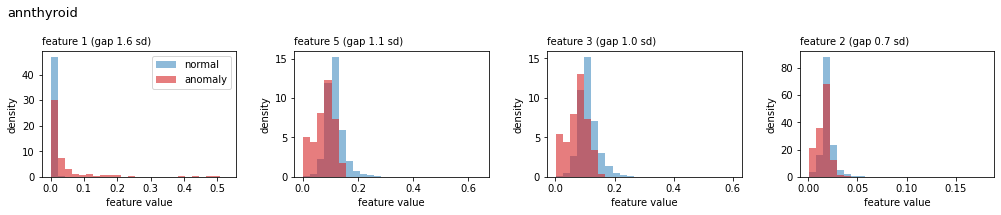

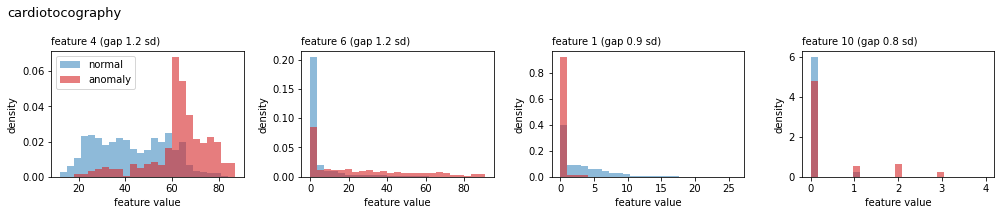

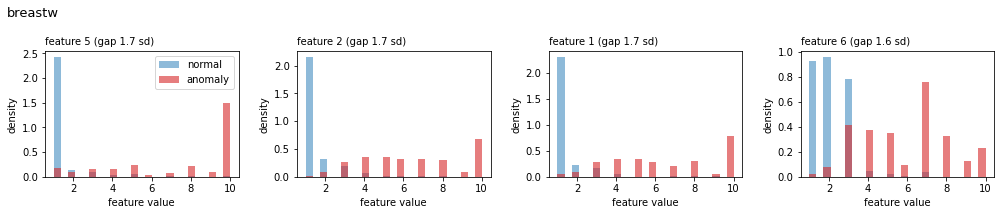

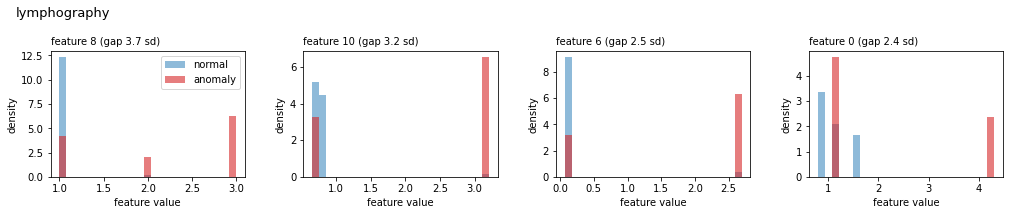

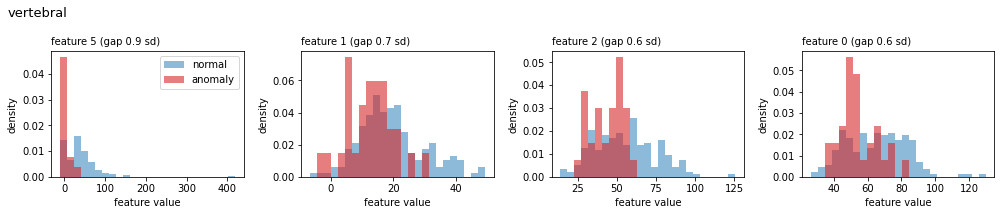

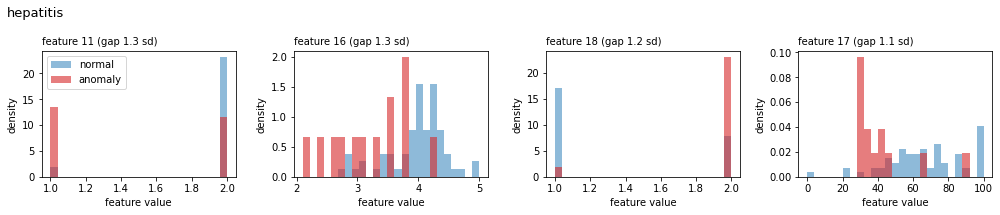

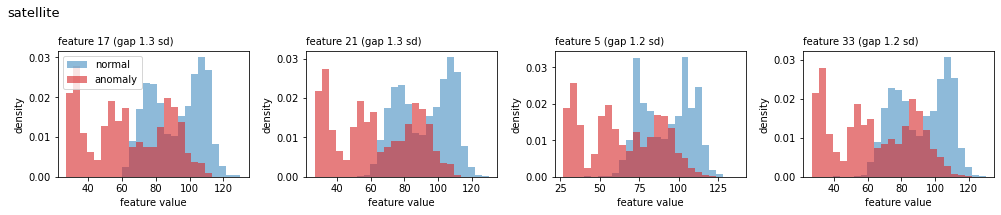

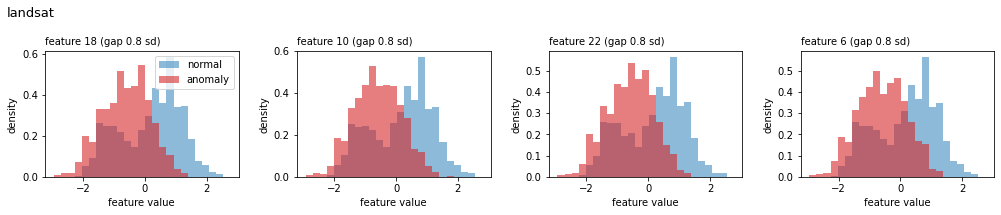

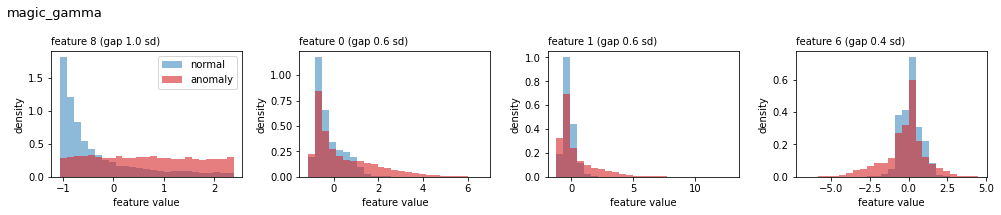

In [15]:
def plot_top_features(name,X,y,n_top=4):
    X_scaled=(X-X.mean(0))/(X.std(0)+1e-12)
    gap=np.abs(X_scaled[y==1].mean(0)-X_scaled[y==0].mean(0))
    top=np.argsort(gap)[::-1][:n_top]
    fig,axes=plt.subplots(1,n_top,figsize=(14,3))
    for ax,j in zip(axes,top):
        bins=np.histogram_bin_edges(X[:,j],bins=25)
        ax.hist(X[y==0,j],bins=bins,density=True,alpha=0.5,color=NORMAL_COLOR,label="normal")
        ax.hist(X[y==1,j],bins=bins,density=True,alpha=0.6,color=ANOMALY_COLOR,label="anomaly")
        ax.set_title(f"feature {j} (gap {gap[j]:.1f} sd)",loc="left", fontsize=10)
        ax.set_xlabel("feature value")
        ax.set_ylabel("density")
    axes[0].legend()
    fig.suptitle(name,x=0.01,ha="left",fontsize=13)
    fig.tight_layout()
    fig.subplots_adjust(wspace=0.3)
    plt.show()
for name,(X,y) in data.items():
    plot_top_features(name,X,y)

**Feature Scaling: Before vs After**

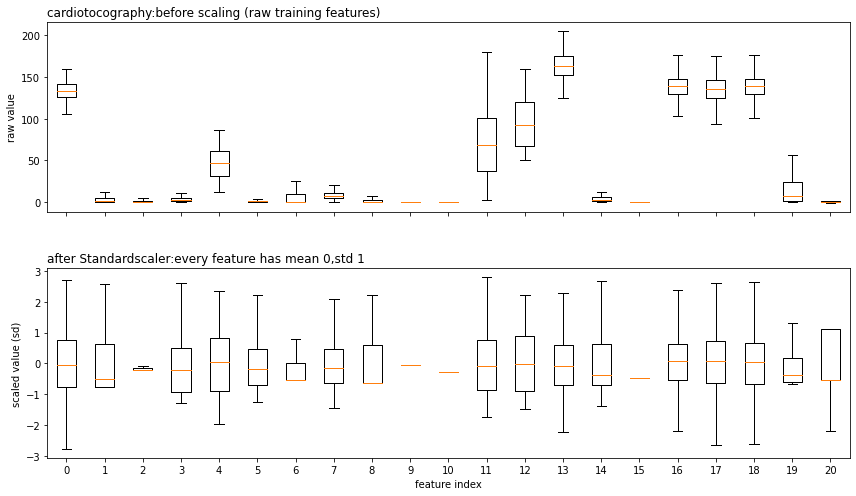

train:mean -0.00,std 1.00
test:mean -0.02,std 1.01


In [16]:
name = "cardiotocography"
X,y=data[name]
X_train,X_test,_,_=split_data(X,y,seed=SEED)
X_train_scaled,X_test_scaled=scale_features(X_train,X_test)
fig,(ax1,ax2)=plt.subplots(2,1,figsize=(12,7),sharex=True)
ax1.boxplot(X_train,showfliers=False)
ax1.set_title(f"{name}:before scaling (raw training features)",loc="left")
ax1.set_ylabel("raw value")

ax2.boxplot(X_train_scaled,showfliers=False)
ax2.set_title("after Standardscaler:every feature has mean 0,std 1",loc="left")
ax2.set_ylabel("scaled value (sd)")
ax2.set_xlabel("feature index")
ax2.set_xticks(range(1,X.shape[1]+1),range(X.shape[1]))

fig.tight_layout()
fig.subplots_adjust(hspace=0.3)
plt.show()

print(f"train:mean {X_train_scaled.mean():.2f},std {X_train_scaled.std():.2f}")
print(f"test:mean {X_test_scaled.mean():.2f},std {X_test_scaled.std():.2f}")



**Labeled Anomalies at each % labeled (Table,Chart)**

In [17]:
rows = []
for name,(X,y) in data.items():
    _,_,y_train,_ = split_data(X,y,seed=SEED)
    for f in LABEL_FRACTIONS:
        _,n_labeled=hide_labels(y_train,f,seed=SEED)
        rows.append({"dataset":name,"fraction":f"{int(f*100)}%","labeled":n_labeled})
counts=pd.DataFrame(rows).pivot(index="dataset",columns="fraction",values="labeled")
counts=counts[[f"{int(f * 100)}%" for f in LABEL_FRACTIONS]].loc[ALL_NAMES]
counts

fraction,1%,5%,10%,25%,50%,100%
dataset,,,,,,
annthyroid,3,18,37,93,187,374
cardiotocography,3,16,32,81,163,326
breastw,1,8,16,41,83,167
lymphography,1,1,1,1,2,4
vertebral,1,1,2,5,10,21
hepatitis,1,1,1,2,4,9
satellite,14,71,142,356,712,1425
landsat,9,46,93,233,466,933
magic_gamma,46,234,468,1170,2341,4682


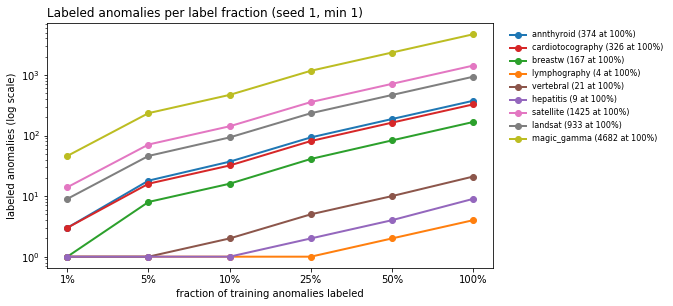

In [18]:
fig,ax = plt.subplots(figsize=(8,4.5))
x_positions=np.arange(len(LABEL_FRACTIONS))
for color,name in zip(LINE_COLORS,counts.index):
    ax.plot(x_positions,counts.loc[name].values,marker="o",linewidth=2,color=color,label=f"{name} ({counts.loc[name].iloc[-1]} at 100%)")
ax.set_yscale("log")
ax.set_xticks(x_positions,counts.columns)
ax.set_xlabel("fraction of training anomalies labeled")
ax.set_ylabel("labeled anomalies (log scale)")
ax.set_title("Labeled anomalies per label fraction (seed 1, min 1)",loc="left")
ax.legend(fontsize=8,loc="upper left",bbox_to_anchor=(1.02,1),frameon=False)
plt.savefig("../results/figures/labeled_anomalies_per_fraction.png",dpi=200,bbox_inches="tight")
plt.show()